# 1. Data Preprocessing

Data preprocessing is an important stage of the project, as the quality and consistency of the data influence the reliability of the subsequent analysis and machine learning models.

In this project, the weekly production dataset is prepared for analysing production performance and predicting actual production quantity (`actual_qty`) in the shoe manufacturing division.

The preprocessing workflow includes:

1. Loading and inspecting the dataset.
2. Checking for duplicate records and missing values.
3. Correcting data types.
4. Creating a meaningful feature for order categorisation.
5. Removing redundant and pre-calculated columns.
6. Identifying and filtering lower outliers in the `rate` column.
7. Saving the preprocessed dataset for subsequent analysis.

These steps establish a consistent dataset for exploratory data analysis and machine learning model development.

## 1.1 Import Libraries and Load Data

The required Python libraries are imported, and the weekly production dataset is loaded into a Pandas DataFrame.

Pandas is used for data manipulation and inspection, NumPy supports numerical operations, and Matplotlib and Seaborn are used for data visualisation.

The dataset's dimensions and first few records are examined to understand its structure and identify the available variables. The dimensions indicate the number of records and columns, while the initial records help verify that the data has been loaded correctly.

This initial inspection provides a starting point for identifying potential data quality issues before performing further preprocessing.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Set visualisation style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Load the raw dataset from the project directory
file_path = Path("../data/raw/DI_Leather_weekly_dataset.csv")
df = pd.read_csv(file_path)

print(f"Initial dataset shape: {df.shape}")

display(df.head())


Initial dataset shape: (9579, 36)


,record_id,financial_year,financial_month,week_no,week_of_month,week_start_date,week_end_date,factory_unit,product_family,is_school,...,machine_count,production_gap_qty,production_gap_value,achievement_rate,efficiency_rate,qty_per_labor_hour,qty_per_machine_hour,cycle_time_mins,takt_time_mins,bottleneck_flag
0,SYN-2022-001338,2022-2023,Apr,3,3,4/18/2022,4/22/2022,Factory Unit 01,Gents,False,...,3,3,74.04,0.869565,0.667,0.0358,0.0117,142.68,3429.54,True
1,SYN-2022-000103,2022-2023,Apr,3,3,4/18/2022,4/22/2022,Factory Unit 01,Ladies,False,...,5,5,21816.75,0.883721,0.776,0.0626,0.0117,123.77,1110.55,True
2,SYN-2022-000540,2022-2023,Apr,3,3,4/18/2022,4/22/2022,Factory Unit 01,Ladies,False,...,5,7,34096.44,0.825000,0.660,0.0403,0.0078,135.93,1236.26,True
3,SYN-2022-000415,2022-2023,Apr,3,3,4/18/2022,4/22/2022,Factory Unit 01,Ladies,False,...,3,6,42022.26,0.880000,0.846,0.0698,0.0218,88.53,2692.28,False
4,SYN-2022-000931,2022-2023,Apr,3,3,4/18/2022,4/22/2022,Factory Unit 01,Gents,False,...,3,4,18707.64,0.885714,0.861,0.0637,0.0188,136.36,6610.68,False


## 1.2 Check Duplicates and Missing Values

The dataset is examined for exact duplicate records and missing values.

**Duplicate records:** Exact duplicates may cause the same observation to be counted more than once, potentially affecting statistical summaries and model training. The code identifies and removes exact duplicate rows.

**Missing values:** Missing values are checked across the columns to determine whether information is incomplete. Missing data may affect calculations, visualisations, and machine learning algorithms, depending on the variable and the method used.

The missing-value summary is inspected to understand the extent of missing information. This step focuses on identifying missing values; it does not automatically imply that missing values are removed or imputed.

Completing these checks helps establish a clearer understanding of the dataset's quality before proceeding.

In [2]:
# Check for exact duplicate rows
duplicates = df.duplicated().sum()
print(f"Number of exact duplicate rows: {duplicates}")

# Remove duplicates if any exist
if duplicates > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"Shape after removing duplicates: {df.shape}")

# Check for missing values
missing_values = df.isnull().sum()
missing_pct = (missing_values / len(df)) * 100

# Display columns with missing values
missing_df = pd.DataFrame({'Missing_Count': missing_values, 'Missing_Percent': missing_pct})
missing_df = missing_df[missing_df['Missing_Count'] > 0].sort_values(by='Missing_Count', ascending=False)

if not missing_df.empty:
    print("\nColumns with missing values:")
    print(missing_df)
else:
    print("\nNo missing values found in the dataset.")

Number of exact duplicate rows: 0

No missing values found in the dataset.


## 1.3 Correct Data Types

The data types of selected columns are standardised to ensure that the variables can be used appropriately in subsequent analysis.

Date columns are converted into a date format so that they can support chronological analysis and time-based ordering. Boolean columns are converted from text representations such as `TRUE` and `FALSE` into consistent Boolean values.

Correct data types are important because values stored in an inappropriate format may not behave as expected during calculations, filtering, grouping, or feature engineering.

This step improves consistency in the representation of dates and Boolean indicators. The date conversion also depends on the format specified in the code, so the input dates must follow that expected format.

In [3]:


# Convert date columns to datetime
date_cols = ["week_start_date", "week_end_date"]

for col in date_cols:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="raise")

# Convert Boolean columns safely
bool_cols = ["is_school", "is_forces_police", "bottleneck_flag"]

for col in bool_cols:
    if col not in df.columns:
        print(f"Skipping '{col}': column not present in the current dataset.")
        continue

    if pd.api.types.is_bool_dtype(df[col]):
        continue

    # Standardise text representations of Boolean values
    values = df[col].astype(str).str.strip().str.upper()

    converted = values.map({
        "TRUE": True,
        "FALSE": False,
        "1": True,
        "0": False
    })

    if converted.isna().any():
        unexpected = values[converted.isna()].unique().tolist()
        raise ValueError(
            f"Unexpected values in '{col}': {unexpected}. "
            "Inspect these values before conversion."
        )

    df[col] = converted.astype(bool)

print("Data type conversion completed.")
print("\nRelevant columns currently available:")
print([col for col in date_cols + bool_cols if col in df.columns])

display(df.dtypes.to_frame(name="Data Type"))



Data type conversion completed.

Relevant columns currently available:
['week_start_date', 'week_end_date', 'is_school', 'is_forces_police', 'bottleneck_flag']


,Data Type
record_id,str
financial_year,str
financial_month,str
week_no,int64
week_of_month,int64
week_start_date,datetime64[us]
week_end_date,datetime64[us]
factory_unit,str
product_family,str
is_school,bool


## 1.4 Feature Engineering and Column Selection

Feature engineering involves creating useful variables from information already available in the dataset. These variables can help describe production records more meaningfully during exploratory data analysis and modelling.

In this step, a new categorical feature, `order_category`, is created using the existing order indicators. Selected redundant, unnecessary, and pre-calculated columns are then removed.

Column selection helps simplify the dataset and reduces the inclusion of variables that are not required for the planned analysis. Particular care is needed with metrics calculated from actual production outcomes, because using information that would not be available at prediction time can lead to data leakage.

The modelling target for this project is `actual_qty`, representing the actual production quantity. The remaining variables should be evaluated according to whether they are relevant and available when a production prediction is made.

### 1.4.1 Create the `order_category` Feature

The `order_category` feature is created using the existing `is_school` and `is_forces_police` indicators.

The classification follows the conditions specified in the code:

- **School:** Assigned when `is_school` satisfies the specified condition.
- **Forces/Police:** Assigned when `is_forces_police` satisfies the specified condition.
- **Others:** Assigned when neither condition is satisfied.

The resulting feature represents order categories using a single categorical column instead of requiring the two original indicators to be examined separately.

This feature can help investigate whether production characteristics differ across order categories during exploratory data analysis.

The category assignment follows the order of conditions in `np.select`, meaning that if both conditions are satisfied, the first matching condition takes precedence.

In [4]:
# Feature Engineering: Create 'order_category'

conditions = [
    (df['is_school'] == True),
    (df['is_forces_police'] == True)
]
choices = ['School', 'Forces/Police']

# Create the new column, defaulting to 'Others' if both are False
df['order_category'] = np.select(conditions, choices, default='Others')

print("Created 'order_category' column.")
print(df['order_category'].value_counts())
print("-" * 30)

Created 'order_category' column.
order_category
Others           7921
Forces/Police    1470
School            188
Name: count, dtype: int64
------------------------------


### 1.4.2 Remove Redundant and Pre-calculated Columns

Selected columns are removed to simplify the dataset and retain the variables required for the subsequent analysis.

The columns removed by the code include identifiers, redundant order indicators, selected planning and value-related columns, and pre-calculated production metrics.

Removing unnecessary columns can reduce duplication of information and make the dataset easier to analyse. However, a column should not be removed solely because it is numerical or derived; its relevance to the research objective and prediction process should also be considered.

The target variable is `actual_qty`. Metrics calculated using actual production outcomes, such as `actual_value`, production-gap measures, achievement measures, and production-efficiency measures, may introduce data leakage if they are used as predictors when making future predictions.

Therefore, predictors should represent information available at the time the prediction is generated. Planning variables may be useful if they are known in advance, while variables calculated after production is completed should be excluded from the predictor set.

The code removes the listed columns that are present in the DataFrame. The resulting dataset is then used for the remaining preprocessing steps.

In [5]:

# Remove redundant, identifier, and pre-calculated columns

cols_to_drop = [
    "record_id",
    "planned_value",
    "actual_value",
    "production_gap_value",
    "monthly_plan_qty",
    "is_school",
    "is_forces_police",
    "labor_hours",
    "overtime_hours",
    "achievement_rate",
    "efficiency_rate",
    "qty_per_labor_hour",
    "qty_per_machine_hour",
    "cycle_time_mins",
    "takt_time_mins"
]

# Drop only columns that exist in the dataset
cols_to_drop_existing = [
    col for col in cols_to_drop if col in df.columns
]

cols_not_found = [
    col for col in cols_to_drop if col not in df.columns
]

df = df.drop(columns=cols_to_drop_existing)

print("Columns removed:")
print(cols_to_drop_existing)

if cols_not_found:
    print("\nRequested columns not found:")
    print(cols_not_found)

print(f"\nDataset shape after column removal: {df.shape}")
print("\nRemaining columns:")
print(df.columns.tolist())


Columns removed:
['record_id', 'planned_value', 'actual_value', 'production_gap_value', 'monthly_plan_qty', 'is_school', 'is_forces_police', 'labor_hours', 'overtime_hours', 'achievement_rate', 'efficiency_rate', 'qty_per_labor_hour', 'qty_per_machine_hour', 'cycle_time_mins', 'takt_time_mins']

Dataset shape after column removal: (9579, 22)

Remaining columns:
['financial_year', 'financial_month', 'week_no', 'week_of_month', 'week_start_date', 'week_end_date', 'factory_unit', 'product_family', 'item_name', 'size_id', 'grade', 'planned_qty', 'rate', 'actual_qty', 'no_of_workers', 'working_hours', 'total_duration_per_shoe_mins', 'machine_capacity_per_day', 'machine_count', 'production_gap_qty', 'bottleneck_flag', 'order_category']



## 1.5 Outlier Detection and Removal

Outlier detection is performed on the `rate` column using the Interquartile Range (IQR) method.

The first quartile (Q1) and third quartile (Q3) are used to calculate the IQR:

- **IQR:** Q3 − Q1
- **Lower bound:** Q1 − 1.5 × IQR
- **Upper bound:** Q3 + 1.5 × IQR

In this notebook, only observations with `rate` values below the lower bound are removed. Observations above the upper bound are retained.

An observation identified as a statistical outlier is not necessarily an incorrect record. In a manufacturing context, unusually low rates may reflect genuine production conditions. Therefore, the effect of this filtering step should be considered when interpreting the subsequent analysis and modelling results.


### 1.5.1 Visualise the `rate` Distribution Before Filtering

A boxplot and histogram are generated to examine the original distribution of the `rate` column.

The boxplot helps identify the spread of the values, the median, and observations that may be potential outliers. The histogram shows how frequently different values occur and provides an overview of the distribution's shape.

Examining both visualisations helps identify the presence of unusually low values before applying the statistical filtering rule.

These plots provide a baseline for comparison with the distribution after filtering.

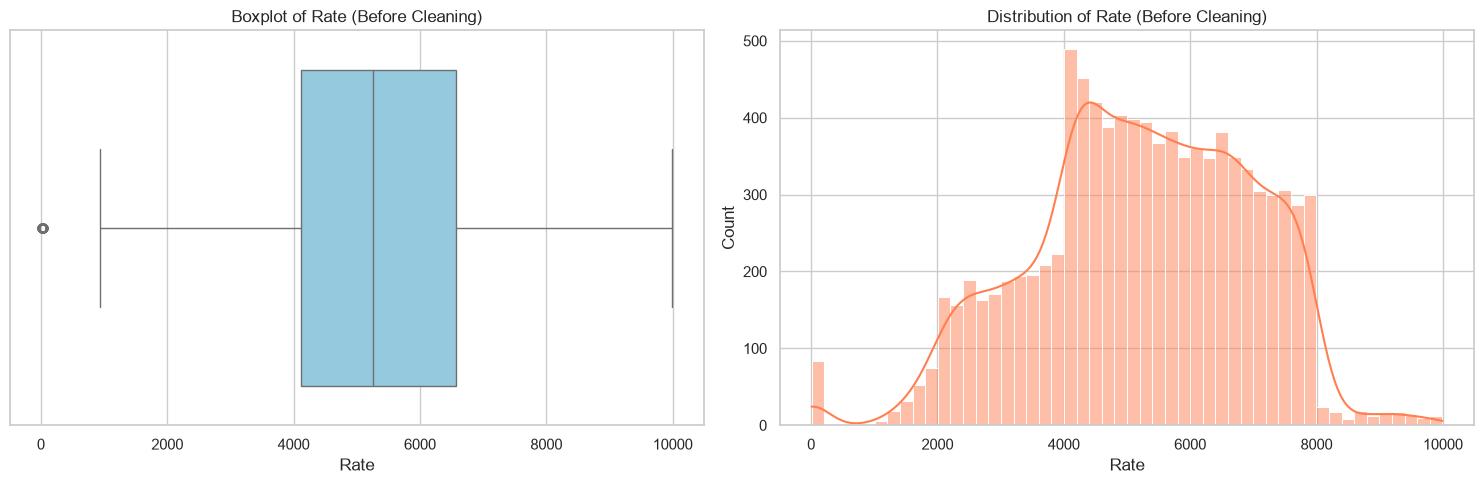

In [6]:
# 1. Visualize the 'rate' column before cleaning
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Boxplot
sns.boxplot(x=df['rate'], ax=axes[0], color='skyblue')
axes[0].set_title('Boxplot of Rate (Before Cleaning)')
axes[0].set_xlabel('Rate')

# Histogram
sns.histplot(df['rate'], bins=50, kde=True, ax=axes[1], color='coral')
axes[1].set_title('Distribution of Rate (Before Cleaning)')
axes[1].set_xlabel('Rate')

plt.tight_layout()
plt.show()

### 1.5.2 Calculate the IQR Boundary and Filter Lower Outliers

The Interquartile Range (IQR) method is applied to calculate the lower boundary for identifying potential outliers in the `rate` column.

The method uses the following calculations:

- **First Quartile (Q1):** The 25th percentile of the data.
- **Third Quartile (Q3):** The 75th percentile of the data.
- **Interquartile Range:** The difference between Q3 and Q1.
- **Lower Bound:** Q1 − 1.5 × IQR.
- **Upper Bound:** Q3 + 1.5 × IQR.

The IQR represents the spread of the middle 50% of observations. The calculated boundaries provide a consistent statistical rule for identifying values that fall unusually far from this central range.

The code retains records where `rate` is greater than or equal to the lower bound. Consequently, observations below the lower bound are removed, while observations above the upper bound remain in the dataset.

This operation focuses specifically on lower outliers. The choice to filter these observations should be considered in relation to the production context, because unusually low values may contain meaningful information about production challenges.

In [7]:

# Calculate the IQR boundaries for the rate column

if df["rate"].isna().any():
    raise ValueError(
        "The rate column contains missing values. "
        "Handle them before applying IQR filtering."
    )

Q1 = df["rate"].quantile(0.25)
Q3 = df["rate"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Q1: {Q1:.2f}")
print(f"Q3: {Q3:.2f}")
print(f"IQR: {IQR:.2f}")
print(f"Lower bound: {lower_bound:.2f}")
print(f"Upper bound: {upper_bound:.2f}")

# Filter lower outliers only
rows_before = len(df)

df_clean = df[df["rate"] >= lower_bound].copy()

rows_removed = rows_before - len(df_clean)

print(f"\nRows before filtering: {rows_before}")
print(f"Lower-outlier rows removed: {rows_removed}")
print(f"Rows after filtering: {len(df_clean)}")
print(f"Final shape at this stage: {df_clean.shape}")


Q1: 4110.00
Q3: 6564.73
IQR: 2454.73
Lower bound: 427.91
Upper bound: 10246.82

Rows before filtering: 9579
Lower-outlier rows removed: 84
Rows after filtering: 9495
Final shape at this stage: (9495, 22)


 ### 1.5.3 Visualise the `rate` Distribution After Filtering

The boxplot and histogram are generated again using the filtered dataset.

Comparing the visualisations before and after filtering helps assess how removing values below the lower bound has affected the distribution of `rate`.

The boxplot can show changes in the lower tail and the range of the observations, while the histogram helps reveal changes in the frequency distribution.

This comparison supports an understanding of the effect of the filtering operation. It does not, by itself, establish that every removed observation was an error or that the resulting data is necessarily more representative of actual production conditions.

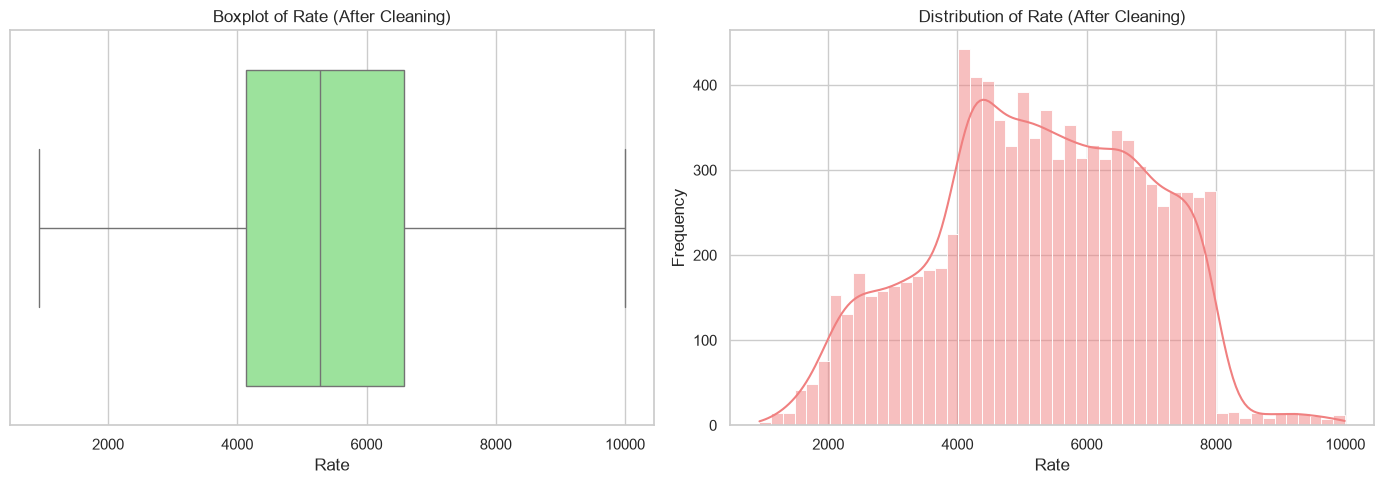

In [8]:
# 4. Visualize the 'rate' column after cleaning
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot
sns.boxplot(x=df_clean['rate'], ax=axes[0], color='lightgreen')
axes[0].set_title('Boxplot of Rate (After Cleaning)')
axes[0].set_xlabel('Rate')

# Histogram
sns.histplot(df_clean['rate'], bins=50, kde=True, ax=axes[1], color='lightcoral')
axes[1].set_title('Distribution of Rate (After Cleaning)')
axes[1].set_xlabel('Rate')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

## 1.6 Finalise and Save the Preprocessed Dataset

After the preprocessing steps are completed, the DataFrame index is reset and the resulting dataset is saved as `DI_Leather_preprocessed.csv`.

Resetting the index provides a fresh sequential index for the resulting DataFrame after records have been removed. The CSV file preserves the preprocessed data so that it can be loaded into subsequent notebooks without repeating these steps.

The saved dataset serves as the input for the next stages of the project, including exploratory data analysis, feature preparation, and machine learning model development.

The target variable for the modelling stage remains `actual_qty`. Subsequent modelling steps must also ensure that predictors contain only information available at the time production predictions are made.

In [9]:


# Reset index after preprocessing
df_clean = df_clean.reset_index(drop=True)

# Define the output path
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

cleaned_file_path = output_dir / "DI_Leather_preprocessed.csv"

# Save the preprocessed dataset
df_clean.to_csv(cleaned_file_path, index=False)

print("Preprocessing complete!")
print(f"Final dataset shape: {df_clean.shape}")
print(f"Number of records: {len(df_clean)}")
print(f"Number of columns: {len(df_clean.columns)}")
print(f"Cleaned dataset saved to: {cleaned_file_path.resolve()}")

display(df_clean.head())



Preprocessing complete!
Final dataset shape: (9495, 22)
Number of records: 9495
Number of columns: 22
Cleaned dataset saved to: C:\Production-DI Leather\production-DI\data\processed\DI_Leather_preprocessed.csv


,financial_year,financial_month,week_no,week_of_month,week_start_date,week_end_date,factory_unit,product_family,item_name,size_id,...,rate,actual_qty,no_of_workers,working_hours,total_duration_per_shoe_mins,machine_capacity_per_day,machine_count,production_gap_qty,bottleneck_flag,order_category
0,2022-2023,Apr,3,3,2022-04-18,2022-04-22,Factory Unit 01,Ladies,BINOLI (VAST) - BROWN,12,...,4363.35,38,15,647.82,114.50,200,5,5,True,Others
1,2022-2023,Apr,3,3,2022-04-18,2022-04-22,Factory Unit 01,Ladies,BINOLI - L - BLACK,7,...,4870.92,33,23,844.78,123.14,200,5,7,True,Others
2,2022-2023,Apr,3,3,2022-04-18,2022-04-22,Factory Unit 01,Ladies,BINOLI - L - GREEN,9,...,7003.71,44,15,673.07,89.04,200,3,6,False,Others
3,2022-2023,Apr,3,3,2022-04-18,2022-04-22,Factory Unit 01,Gents,BOOT HIGH LEG - BLACK,13,...,4676.91,31,11,550.89,125.18,200,3,4,False,Forces/Police
4,2022-2023,Apr,3,3,2022-04-18,2022-04-22,Factory Unit 01,Gents,BOOT HIGH LEG - L - BLACK,13,...,3803.13,36,18,813.02,117.33,200,5,4,True,Forces/Police
